---
title: "Complex Functions, Probability and Wave Packets"
short_title: "Q-M1 Complex Functions & Wave Packets"
numbering:
  heading_2: true
  equation: true
---

# Complex Functions, Probability and Wave Packets

:::{tip} Where this sits in the plan
Math for **the wave function** and **wells and tunneling** (quantum topics 1 and 2). Complex numbers first appear in mechanics M1 and M4, Fourier transforms in E&M E-M3, and Gaussian integrals in thermo T-M2; this notebook puts them together the way quantum mechanics uses them.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Complex numbers and Euler's formula | App. H | 2 | 17 | 11 |
| Probability and distributions | – | 15 | – | 23 |
| Gaussian integrals | 15 | 11 | – | 13 |
| Fourier transforms | – | 7 | 15 | 20 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [The Wave Function](../qm/01-wave-function.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Complex-Valued Functions**

   (a) Find the modulus and the phase of $(3 + 4i)e^{ikx}$.

   (b) Are $\Psi$ and $-\Psi$ physically different states? Are $\psi_1 + \psi_2$ and $\psi_1 - \psi_2$? Explain.

2. **Probability Densities**

   The probability density $\rho(x) = Axe^{-x/a}$ holds for $x > 0$ (and $\rho = 0$ for $x < 0$).

   (a) Find $A$.

   (b) Find $\langle x\rangle$, $\langle x^2\rangle$ and $\sigma$.

3. **Fourier Transforms and Momentum Space**

   Use $\Phi(p) = \dfrac{1}{\sqrt{2\pi\hbar}}\displaystyle\int\Psi(x)\,e^{-ipx/\hbar}\,dx$.

   (a) Find $\Phi(p)$ for $\Psi = 1/\sqrt{2a}$ on $|x| < a$ (and $0$ outside).

   (b) A Gaussian packet is made half as wide in $x$. What happens to $\sigma_p$, and to the product $\sigma_x\sigma_p$?

4. **Expectation Values with Derivatives**

   For $\Psi = Ae^{-x^2/4\sigma^2}e^{ik_0x}$, find $\langle p\rangle$ and $\langle p^2\rangle$ using $\hat p = -i\hbar\,\partial_x$.

5. **Phase Velocity, Group Velocity and Spreading**

   (a) A free Gaussian packet spreads as $\sigma(t) = \sigma_0\sqrt{1 + \left(\hbar t/2m\sigma_0^2\right)^2}$. How long until a proton packet with $\sigma_0 = 1$ nm doubles in width?

   (b) Compare the group and phase velocities of a free matter wave with the particle's classical velocity.

:::{dropdown} Answers
1. (a) The modulus is $5$, and the phase is $kx + \arctan(4/3)$.

   (b) $\Psi$ and $-\Psi$ are the same state, since a global phase is unobservable. $\psi_1 \pm \psi_2$ are different states: the relative phase changes $|\Psi|^2$ through the interference term.

2. (a) $\int_0^\infty xe^{-x/a}\,dx = a^2$, so $A = 1/a^2$.

   (b) $\langle x\rangle = 2a$, $\langle x^2\rangle = 6a^2$ and $\sigma = \sqrt2\,a$.

3. (a) $\Phi(p) = \sqrt{\dfrac{\hbar}{\pi a}}\,\dfrac{\sin(pa/\hbar)}{p}$.

   (b) $\sigma_p$ doubles, and the product stays at $\hbar/2$.

4. $\langle p\rangle = \hbar k_0$ and $\langle p^2\rangle = \hbar^2k_0^2 + \dfrac{\hbar^2}{4\sigma^2}$.

5. (a) Doubling needs $\hbar t/(2m\sigma_0^2) = \sqrt3$, so $t = 2\sqrt3\,m\sigma_0^2/\hbar \approx 5\times10^{-11}$ s.

   (b) The group velocity is $p/m$, the classical velocity. The phase velocity is half that.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Complex-Valued Functions

A wave function $\Psi(x)$ assigns a complex number to each point. Write it in polar form,

$$
\Psi(x) = R(x)\,e^{i\phi(x)},\qquad R = |\Psi|\ge0 ,
$$ (eq-polar-psi)

with modulus $R$ and phase $\phi$. The two parts play different roles:

- $|\Psi|^2 = \Psi^*\Psi = R^2$ is real and non-negative, and becomes a probability density.
- The phase is invisible in $|\Psi|^2$, but its *gradient* carries momentum: for $\Psi = e^{ikx}$, $|\Psi|^2 = 1$ everywhere, yet the state has definite momentum $\hbar k$.

Three facts used constantly:

$$
|zw| = |z||w|,\qquad |e^{i\theta}| = 1,\qquad (zw)^* = z^*w^* .
$$ (eq-complex-facts)

Multiplying a wave function by a constant phase $e^{i\alpha}$ changes nothing measurable (a **global phase**). A phase that varies with $x$ is a different matter.

## Probability Densities

For a continuous variable with density $\rho(x)$:

$$
P(a\le x\le b) = \int_a^b\rho(x)\,dx,\qquad\int_{-\infty}^\infty\rho\,dx = 1,\qquad\langle f(x)\rangle = \int f(x)\rho(x)\,dx .
$$ (eq-density-rules)

The standard deviation $\sigma = \sqrt{\langle x^2\rangle - \langle x\rangle^2}$ measures spread. In quantum mechanics $\rho = |\Psi|^2$, and "expectation value" means the average over many identically prepared systems, not the average of repeated measurements on one.

::::{prf:example} Normalizing a Gaussian
:label: ex-normalize-gaussian

Find $A$ so that $\Psi(x) = Ae^{-x^2/4\sigma^2}e^{ik_0x}$ is normalized, then find $\langle x\rangle$ and the spread of $|\Psi|^2$.

:::{dropdown} Solution
The phase drops out of $|\Psi|^2 = |A|^2e^{-x^2/2\sigma^2}$. With the Gaussian integral (T-M2), $\int e^{-x^2/2\sigma^2}dx = \sqrt{2\pi}\,\sigma$, so $|A|^2 = 1/(\sqrt{2\pi}\sigma)$ and $A = (2\pi\sigma^2)^{-1/4}$ (choosing $A$ real).

$|\Psi|^2$ is a normal distribution with mean $0$ and standard deviation $\sigma$, so $\langle x\rangle = 0$ and $\sigma_x = \sigma$. (The $4\sigma^2$ in $\Psi$ becomes $2\sigma^2$ in $|\Psi|^2$; that factor of 2 is a frequent slip.)
:::
::::

In [2]:
x, s, k0 = sp.symbols("x sigma k_0", positive=True)
A = (2 * sp.pi * s**2)**sp.Rational(-1, 4)
psi = A * sp.exp(-x**2 / (4 * s**2)) * sp.exp(sp.I * k0 * x)
rho = sp.simplify(psi * sp.conjugate(psi))
norm = sp.integrate(rho, (x, -sp.oo, sp.oo))
x2 = sp.integrate(x**2 * rho, (x, -sp.oo, sp.oo))
display(Math(r"|\Psi|^2 = " + sp.latex(rho) + r",\qquad \int|\Psi|^2dx = " + sp.latex(sp.simplify(norm)) + r",\qquad \langle x^2\rangle = " + sp.latex(sp.simplify(x2))))

<IPython.core.display.Math object>

## Fourier Transforms and Momentum Space

E-M3 introduced the Fourier transform as a decomposition into plane waves. Quantum mechanics uses it with $p = \hbar k$ and a symmetric convention:

$$
\Phi(p) = \frac{1}{\sqrt{2\pi\hbar}}\int_{-\infty}^{\infty}\Psi(x)\,e^{-ipx/\hbar}\,dx,\qquad
\Psi(x) = \frac{1}{\sqrt{2\pi\hbar}}\int_{-\infty}^{\infty}\Phi(p)\,e^{ipx/\hbar}\,dp .
$$ (eq-momentum-space)

$\Phi(p)$ is the **momentum-space wave function**: $|\Phi(p)|^2$ is the probability density for momentum. The symmetric $1/\sqrt{2\pi\hbar}$ makes the transform preserve normalization.

:::{prf:theorem} Plancherel (Parseval)
:label: thm-plancherel

$$
\int_{-\infty}^\infty|\Psi(x)|^2\,dx = \int_{-\infty}^\infty|\Phi(p)|^2\,dp .
$$ (eq-plancherel)
:::

So if $\Psi$ is normalized, $\Phi$ is too, and position and momentum probabilities are two views of one state.

### The Gaussian packet and the width relation

Using the completed-square Gaussian integral (T-M2) with an imaginary linear term, the Gaussian of the example transforms into another Gaussian:

$$
\Phi(p) = \left(\frac{2\sigma^2}{\pi\hbar^2}\right)^{1/4}e^{-\sigma^2(p - \hbar k_0)^2/\hbar^2} .
$$ (eq-gaussian-phi)

Its width in momentum is $\sigma_p = \hbar/2\sigma$, so

$$
\sigma_x\sigma_p = \frac\hbar2 .
$$ (eq-gaussian-min-uncertainty)

A narrow packet has a broad spread of momenta and vice versa. Quantum topic 4 proves $\sigma_x\sigma_p\ge\hbar/2$ for every state; the Gaussian is the case of equality.

In [3]:
p, hb = sp.symbols("p hbar", positive=True)
Phi = sp.simplify(sp.integrate(psi * sp.exp(-sp.I * p * x / hb), (x, -sp.oo, sp.oo)) / sp.sqrt(2 * sp.pi * hb))
display(Math(r"\Phi(p) = " + sp.latex(Phi)))
rhop = sp.simplify(Phi * sp.conjugate(Phi))
display(Math(r"\int|\Phi|^2dp = " + sp.latex(sp.simplify(sp.integrate(rhop, (p, -sp.oo, sp.oo))))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

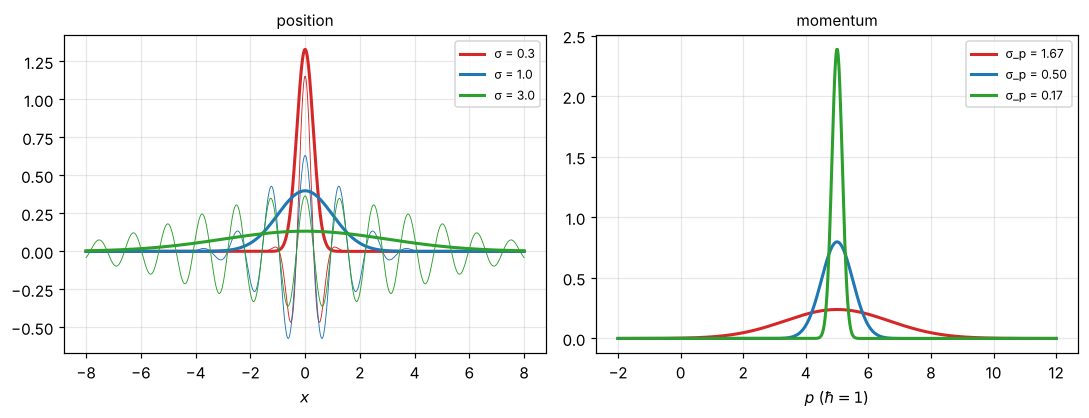

In [4]:
#| label: fig-packet-widths
#| caption: "Three Gaussian wave packets with the same mean momentum (k₀ = 5, ħ = 1) and position widths σ = 0.3, 1 and 3. Left, Re Ψ (thin) and |Ψ|² (thick); right, |Φ(p)|². Squeezing the packet in x spreads it in p, keeping σ_x σ_p = ½."
xx = np.linspace(-8, 8, 1200); pp = np.linspace(-2, 12, 600)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.9))
for sg, col in [(0.3, "tab:red"), (1.0, "tab:blue"), (3.0, "tab:green")]:
    ps = (2 * np.pi * sg**2)**-0.25 * np.exp(-xx**2 / (4 * sg**2) + 5j * xx)
    a1.plot(xx, ps.real, color=col, lw=0.6); a1.plot(xx, abs(ps)**2, color=col, lw=2, label=f"σ = {sg}")
    ph2 = np.sqrt(2 * sg**2 / np.pi) * np.exp(-2 * sg**2 * (pp - 5)**2)
    a2.plot(pp, ph2, color=col, lw=2, label=f"σ_p = {0.5 / sg:.2f}")
a1.set_xlabel("$x$"); a1.legend(fontsize=8); a2.set_xlabel("$p$ ($\\hbar = 1$)"); a2.legend(fontsize=8)
a1.set_title("position", fontsize=10); a2.set_title("momentum", fontsize=10)
plt.tight_layout(); plt.show()

## Expectation Values with Derivatives

In position space, momentum acts as a derivative (quantum topic 1 motivates this):

$$
\langle p\rangle = \int\Psi^*\left(-i\hbar\frac{\partial}{\partial x}\right)\Psi\,dx = \int p\,|\Phi(p)|^2\,dp .
$$ (eq-p-expectation)

Two habits make these integrals painless:

1. **Integrate by parts and drop boundary terms**, because a normalizable $\Psi$ vanishes at $\pm\infty$. For example, $\int\Psi^*\Psi''\,dx = -\int|\Psi'|^2\,dx$, so $\langle p^2\rangle = \hbar^2\int|\Psi'|^2dx\ge0$.
2. **Use symmetry.** If $|\Psi|^2$ is even, odd moments of $x$ vanish. If $\Psi$ is real (up to a global phase), $\langle p\rangle = 0$, because $-i\hbar\int\Psi\Psi'dx = -\tfrac{i\hbar}{2}[\Psi^2]_{-\infty}^\infty = 0$.

In [5]:
# <p> and <p^2> for the Gaussian packet, in position space
pexp = sp.simplify(sp.integrate(sp.conjugate(psi) * (-sp.I * hb) * sp.diff(psi, x), (x, -sp.oo, sp.oo)))
p2exp = sp.simplify(sp.integrate(sp.conjugate(psi) * (-hb**2) * sp.diff(psi, x, 2), (x, -sp.oo, sp.oo)))
sig_p = sp.sqrt(sp.simplify(p2exp - pexp**2))
display(Math(r"\langle p\rangle = " + sp.latex(pexp) + r",\quad \langle p^2\rangle = " + sp.latex(sp.expand(p2exp)) + r",\quad \sigma_x\sigma_p = " + sp.latex(sp.simplify(s * sig_p))))

<IPython.core.display.Math object>

## Phase Velocity, Group Velocity and Spreading

A free particle's plane waves $e^{i(kx - \omega t)}$ obey $\hbar\omega = \hbar^2k^2/2m$, a dispersive relation (E-M3). So:

- crests move at the **phase velocity** $\omega/k = \hbar k/2m$, half the classical speed;
- the envelope moves at the **group velocity** $d\omega/dk = \hbar k/m = p/m$, the classical speed;
- the packet **spreads**: a Gaussian's width grows as $\sigma(t) = \sigma\sqrt{1 + (\hbar t/2m\sigma^2)^2}$.

Narrow packets spread fastest, because they contain the widest range of momenta. The next cell evolves a packet exactly by multiplying its Fourier components by $e^{-i\hbar k^2t/2m}$, the method quantum topic 2 uses for the free particle.

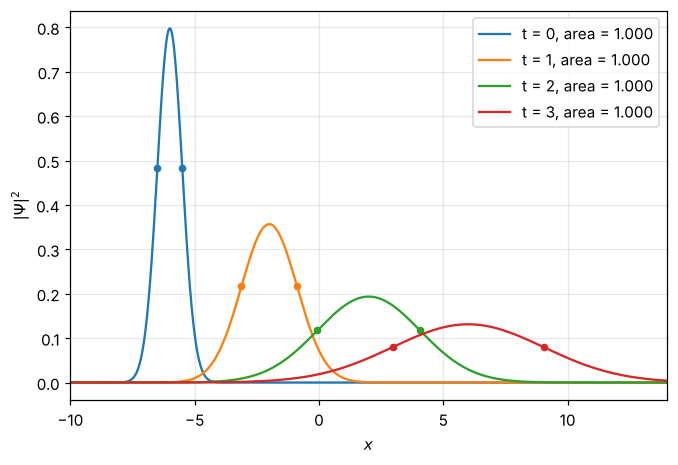

In [6]:
#| label: fig-free-spreading
#| caption: "A free Gaussian packet (ħ = m = 1, σ = 0.5, k₀ = 4) evolved exactly with the FFT at t = 0, 1, 2, 3. The peak moves at the group velocity ħk₀/m = 4 and the width follows σ√(1 + (t/2σ²)²) (dots mark ± one predicted width), while the area stays 1."
N_ = 4096; L_ = 120.0
xg = np.linspace(-L_ / 2, L_ / 2, N_, endpoint=False); dx = xg[1] - xg[0]
kg = 2 * np.pi * np.fft.fftfreq(N_, d=dx)
sg, kk0 = 0.5, 4.0
psi0 = (2 * np.pi * sg**2)**-0.25 * np.exp(-(xg + 6)**2 / (4 * sg**2) + 1j * kk0 * xg)
fig, ax = plt.subplots()
for t, col in zip([0, 1, 2, 3], ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    pst = np.fft.ifft(np.fft.fft(psi0) * np.exp(-1j * kg**2 * t / 2))
    rho_t = abs(pst)**2
    ax.plot(xg, rho_t, color=col, label=f"t = {t}, area = {rho_t.sum() * dx:.3f}")
    w = sg * np.sqrt(1 + (t / (2 * sg**2))**2); c_ = -6 + kk0 * t
    ax.plot([c_ - w, c_ + w], [np.interp(c_ - w, xg, rho_t)] * 2, "o", color=col, ms=4)
ax.set_xlim(-10, 14); ax.set_xlabel("$x$"); ax.set_ylabel("$|\\Psi|^2$"); ax.legend(); plt.show()

### Exercises

1. Normalize $\Psi(x) = Ae^{-a|x|}$ and find $\langle x^2\rangle$.
2. For $\Psi(x) = Ae^{-a|x|}$, find $\Phi(p)$. Is it normalized?
3. Show that $\langle p\rangle = 0$ for any real wave function, using integration by parts.
4. A Gaussian packet for an electron has $\sigma = 1$ nm. How long until its width doubles? Repeat for a 1 μg dust grain with $\sigma = 1$ μm.
5. Show that multiplying $\Psi(x)$ by $e^{iqx}$ shifts $\Phi(p)$ by $\hbar q$.

:::{dropdown} Hints
1. $\int_{-\infty}^\infty e^{-2a|x|}dx = 1/a$; $\int_0^\infty x^2e^{-2ax}dx = 2/(2a)^3$.
2. Split at $x = 0$; you should get a Lorentzian.
3. $\Psi\Psi' = \tfrac12(\Psi^2)'$.
4. Width doubles when $\hbar t/2m\sigma^2 = \sqrt3$.
5. Substitute into {eq}`eq-momentum-space` and combine the exponentials.
:::

:::{dropdown} Answers
1. $A = \sqrt a$; $\langle x^2\rangle = 1/(2a^2)$.
2. $\Phi(p) = \sqrt{\dfrac{2}{\pi\hbar}}\,\dfrac{a^{3/2}\hbar^2}{\hbar^2a^2 + p^2}$; yes, by Plancherel.
3. $\langle p\rangle = -i\hbar\int\Psi\Psi'dx = -\tfrac{i\hbar}{2}[\Psi^2]_{-\infty}^\infty = 0$.
4. Electron: $t = 2\sqrt3\,m\sigma^2/\hbar = 3.0\times10^{-14}$ s. Dust grain: $t\approx3\times10^{13}$ s, about a million years.
5. $\Phi_{\text{new}}(p) = \Phi(p - \hbar q)$: the momentum distribution shifts by $\hbar q$ without changing shape.
:::

## Summary

- $\Psi = Re^{i\phi}$: $|\Psi|^2$ is a probability density, the phase gradient carries momentum, and a global phase is unobservable.
- Normalize, then compute $\langle x\rangle$, $\langle x^2\rangle$, $\sigma$ with the usual probability rules.
- $\Phi(p)$ is the Fourier transform with $p = \hbar k$; Plancherel keeps normalization. Gaussians have $\sigma_x\sigma_p = \hbar/2$.
- $\langle p\rangle$ uses $-i\hbar\,\partial_x$; integrate by parts, drop boundary terms, use symmetry.
- Free packets move at $p/m$ and spread, fastest when narrow.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.